# IMDB sentiment: Logistic Regression, SVM, RNN and LSTM

An executable, English-language walkthrough of the shared Python package. The default experiment uses **20,000 train / 5,000 validation / 25,000 test reviews**, seed 42, and no pretrained models or embeddings.

**Colab:** select **Runtime → Change runtime type → GPU**, run this notebook, and upload `imdb-project.zip` when asked. Create that archive using the README instructions. Download the final artifacts before the session ends.

**Local:** open this notebook in the project folder after installing `.[notebook,test]`. Run all cells in order. Each complete execution starts a new output run. To rerun training, rerun from the data/experiment cell to obtain a fresh run.

Set `MODE = "smoke"` below for a quick pipeline check. Smoke metrics are not scientific results.

## 1. Setup and environment

The notebook imports the same code as the CLI. It contains no second implementation of preprocessing, training, or metrics. Colab uploads require the project source ZIP, not just this notebook. Only upload source archives you trust.

In [1]:
from pathlib import Path
import importlib.util
import json
import os
import subprocess
import sys
import zipfile

IN_COLAB = "google.colab" in sys.modules
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "configs" / "default.yaml").exists():
    if not IN_COLAB:
        raise FileNotFoundError("Open this notebook from the project folder.")
    from google.colab import files
    uploaded = files.upload()
    archives = [name for name in uploaded if name.endswith(".zip")]
    if len(archives) != 1:
        raise ValueError("Upload exactly one imdb-project.zip source archive.")
    PROJECT_ROOT = Path("/content/imdb-project")
    PROJECT_ROOT.mkdir(exist_ok=True)
    with zipfile.ZipFile(archives[0]) as archive:
        for member in archive.infolist():
            target = (PROJECT_ROOT / member.filename).resolve()
            if not target.is_relative_to(PROJECT_ROOT.resolve()):
                raise ValueError("Unsafe archive path.")
        archive.extractall(PROJECT_ROOT)
    if not (PROJECT_ROOT / "pyproject.toml").exists():
        raise FileNotFoundError("The ZIP must contain pyproject.toml, src/, and configs/ at its root.")
    os.chdir(PROJECT_ROOT)

if importlib.util.find_spec("imdb_sentiment") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-e", ".[notebook,test]"], check=True)

# Keep downloaded data and plotting caches inside the project.
os.environ.setdefault("HF_HOME", str(PROJECT_ROOT / ".cache" / "huggingface"))
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".cache" / "matplotlib"))
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import pandas as pd
import torch
from IPython.display import display, Image, Markdown
from imdb_sentiment.config import load_config
from imdb_sentiment.reproducibility import get_device, environment, seed_everything
from imdb_sentiment.data import load_data, describe_data, clean_text, tokenize
from imdb_sentiment.experiment import Experiment
from imdb_sentiment.features import encode, make_loaders
from imdb_sentiment.models import create_model
from imdb_sentiment.reporting import compare_results

display(environment(get_device()))

C:\Users\letie\Documents\Journals\NLP\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'python': '3.11.15',
 'platform': 'Windows-10-10.0.26200-SP0',
 'device': 'cuda',
 'gpu': 'NVIDIA GeForce RTX 3060',
 'versions': {'torch': '2.11.0+cu128',
  'datasets': '5.1.0',
  'scikit-learn': '1.9.1',
  'numpy': '2.4.6',
  'pandas': '3.1.0',
  'matplotlib': '3.11.2',
  'PyYAML': '6.0.3',
  'joblib': '1.6.0'},
 'determinism_note': 'Seeds and deterministic cuDNN settings reduce variation; GPU results are not guaranteed bitwise identical across hardware or versions.'}

## 2. Experiment settings

Full mode preserves the task defaults: TF-IDF unigrams/bigrams, 100,000 features; word vocabulary 20,000 including PAD/UNK; first 300 tokens; 128-dimensional embeddings and hidden states; batch size 64; at most eight epochs.

Smoke mode uses 256/64/128 reviews, one epoch, length 64, vocabulary 2,000, and TF-IDF at most 5,000 features with min_df=1. Both modes preserve the official split boundaries. Only validation data selects hyperparameters and checkpoints.

In [2]:
MODE = "full"
config = load_config(PROJECT_ROOT / "configs" / "default.yaml", mode=MODE)
seed_everything(config["seed"])
print(f"Mode: {MODE.upper()}")
print(json.dumps(config, indent=2))
if MODE == "smoke":
    print("PIPELINE CHECK ONLY — do not use these results for scientific conclusions.")
if not torch.cuda.is_available():
    print("CUDA is unavailable: CPU fallback is active. Full training may take substantially longer.")

Mode: FULL
{
  "seed": 42,
  "data": {
    "dataset_name": "stanfordnlp/imdb",
    "validation_fraction": 0.2,
    "lowercase": true,
    "max_vocab_size": 20000,
    "max_seq_len": 300,
    "batch_size": 64,
    "num_workers": 0
  },
  "baselines": {
    "max_features": 100000,
    "ngram_range": [
      1,
      2
    ],
    "min_df": 2,
    "sublinear_tf": true,
    "c_grid": [
      0.1,
      1.0,
      10.0
    ],
    "logistic_max_iter": 1000
  },
  "neural": {
    "embedding_dim": 128,
    "hidden_dim": 128,
    "num_layers": 1,
    "bidirectional": false,
    "dropout": 0.3,
    "epochs": 8,
    "learning_rate": 0.001,
    "optimizer": "adam",
    "weight_decay": 0.0,
    "grad_clip": 1.0,
    "early_stopping_patience": 2,
    "early_stopping_min_delta": 0.0001,
    "selection_metric": "val_loss"
  },
  "device": "auto",
  "output_dir": "outputs"
}


## 3. Data, cleaning, and exploratory analysis

IDs retain the original official split and row position. Train/validation partitioning is stratified with seed 42. Test reviews never enter the training partition. The source is [stanfordnlp/imdb](https://huggingface.co/datasets/stanfordnlp/imdb), with 0 = negative and 1 = positive.

Cleaning decodes HTML entities, replaces HTML tags with spaces, lowercases by default, and normalizes whitespace. Negations remain; no stopword removal, stemming, or lemmatization is applied. Length statistics use the neural word tokenizer before truncation.

Using the latest cached version of the dataset since stanfordnlp/imdb couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'plain_text' at C:\Users\letie\Documents\Journals\NLP\.cache\huggingface\datasets\stanfordnlp___imdb\plain_text\0.0.0\e6281661ce1c48d982bc483cf8a173c1bbeb5d31 (last modified on Wed Oct 28 00:04:34 2026).


FULL run: C:\Users\letie\Documents\Journals\NLP\outputs\full-20261027T170840-4f2309dd
Device: cuda


split  samples  negative  positive  mean_tokens  median_tokens  p95_tokens  truncated_fraction
train    20000     10000     10000    232.64100          174.0      597.00             0.22605
  val     5000      2500      2500    231.07900          173.0      583.05             0.22400
 test    25000     12500     12500    227.09184          171.0      578.00             0.21448


Artifacts: C:\Users\letie\Documents\Journals\NLP\outputs\full-20261027T170840-4f2309dd


,split,samples,negative,positive,mean_tokens,median_tokens,p95_tokens,truncated_fraction
0,train,20000,10000,10000,232.64100,174.0,597.00,0.22605
1,val,5000,2500,2500,231.07900,173.0,583.05,0.22400
2,test,25000,12500,12500,227.09184,171.0,578.00,0.21448


,review_id,text,label,token_count
0,train:23466,after reading tons of good reviews about this ...,1,228
1,train:5405,to be fair they did as well as they could with...,0,150
2,train:2228,"really an amazing pile of pap! a predictable, ...",0,125
3,train:12453,i saw this film last night following a lot of ...,0,152
4,train:19634,one of the greatest film i have seen this year...,1,184


Original: I don't like this.<br />It is NOT good &amp; never engaging!
Cleaned:  i don't like this. it is not good & never engaging!


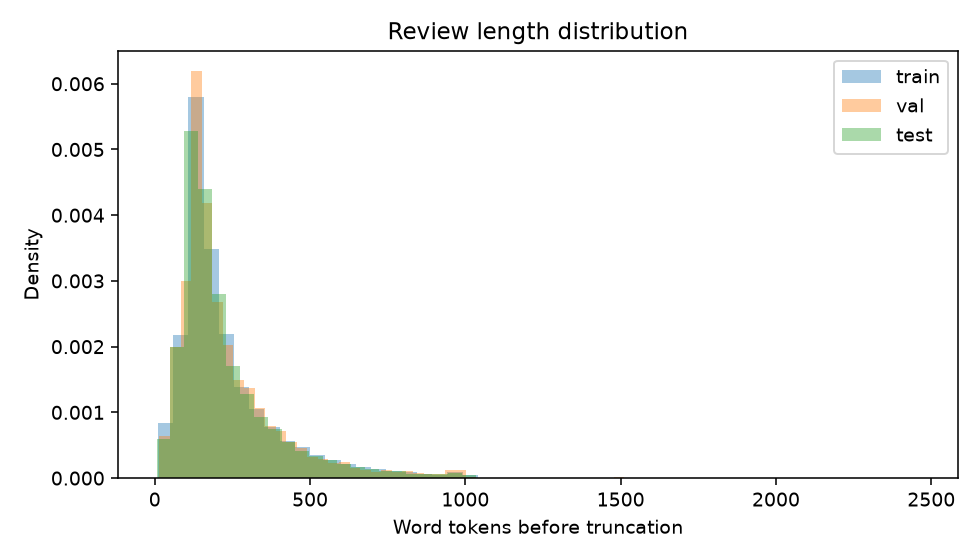

In [3]:
bundle = load_data(config, mode=MODE)
experiment = Experiment(config, bundle, mode=MODE)
RUN_DIR = experiment.directory
print("Artifacts:", RUN_DIR.resolve())
display(describe_data(bundle, config["data"]["max_seq_len"]))
display(bundle.train[["review_id", "text", "label", "token_count"]].head())
example = "I don't like this.<br />It is NOT good &amp; never engaging!"
print("Original:", example)
print("Cleaned: ", clean_text(example))
display(Image(filename=str(RUN_DIR / "review_lengths.png")))
assert bundle.manifest().review_id.is_unique

## 4. Shared input representations

Both linear models share one sparse TF-IDF vectorizer fitted only on training reviews. Scikit-learn's standard TF-IDF token pattern splits contractions; the neural regex keeps forms such as `don't` together. This representation difference is part of the comparison.

RNN/LSTM share one train-only word vocabulary, with PAD=0 and UNK=1. Empty token sequences become [UNK]. Only the first configured number of tokens are retained, which can discard review endings. Padding is dynamic per batch; packed sequences exclude padded positions from recurrence.

In [4]:
tfidf = experiment.prepare_baselines()
vocab = experiment.prepare_neural()
loaders = make_loaders(bundle, vocab, config)
padded_ids, lengths, labels = next(iter(loaders["train"]))
print("Sparse TF-IDF:", tfidf.train.shape, "nonzero values:", tfidf.train.nnz)
print("Vocabulary size (including PAD/UNK):", len(vocab))
print("Neural tokens:", tokenize(clean_text(example)))
print("Encoded:", encode(clean_text(example), vocab, config["data"]["max_seq_len"]))
print("Batch IDs shape:", tuple(padded_ids.shape))
print("Lengths:", lengths[:8].tolist(), "labels dtype:", labels.dtype)
assert lengths.device.type == "cpu"
assert labels.dtype == torch.float32

Sparse TF-IDF: (20000, 100000) nonzero values: 5269054
Vocabulary size (including PAD/UNK): 20000
Neural tokens: ['i', "don't", 'like', 'this', 'it', 'is', 'not', 'good', 'never', 'engaging']
Encoded: [10, 89, 37, 11, 9, 7, 21, 49, 112, 1644]
Batch IDs shape: (64, 300)
Lengths: [300, 115, 300, 223, 300, 107, 47, 265] labels dtype: torch.float32


## 5. Linear baselines

Logistic Regression learns linear log odds; Linear SVM learns a margin-based separator. Each searches C ∈ {0.1, 1, 10} on the same train/validation split. Validation positive-class F1 selects the winner; accuracy and smaller C break ties.

The selected estimator remains fitted on training data only. Test evaluation follows selection. Logistic scores are probabilities; SVM scores are margins, not probabilities.

In [5]:
logreg_model, logreg_metrics, logreg_metadata = experiment.train("logreg")
display(pd.read_csv(RUN_DIR / "logreg" / "hyperparameter_search.csv"))
display(logreg_metadata["best_hyperparameters"])

logreg: C=0.1, validation F1=0.8687


logreg: C=1.0, validation F1=0.8939


logreg: C=10.0, validation F1=0.9033


logreg: test F1=0.9023; artifacts: C:\Users\letie\Documents\Journals\NLP\outputs\full-20261027T170840-4f2309dd\logreg


,C,accuracy,precision,recall,f1,macro_f1,warnings
0,0.1,0.8666,0.855370,0.8824,0.868675,0.866567,NaN
1,1.0,0.8932,0.888231,0.8996,0.893879,0.893196,NaN
2,10.0,0.9028,0.898970,0.9076,0.903264,0.902798,NaN


{'C': 10.0}

In [6]:
svm_model, svm_metrics, svm_metadata = experiment.train("svm")
display(pd.read_csv(RUN_DIR / "svm" / "hyperparameter_search.csv"))
display(svm_metadata["best_hyperparameters"])

svm: C=0.1, validation F1=0.8973


svm: C=1.0, validation F1=0.9054


svm: C=10.0, validation F1=0.9007


svm: test F1=0.9006; artifacts: C:\Users\letie\Documents\Journals\NLP\outputs\full-20261027T170840-4f2309dd\svm


,C,accuracy,precision,recall,f1,macro_f1,warnings
0,0.1,0.8964,0.889238,0.9056,0.897344,0.896391,NaN
1,1.0,0.9052,0.903264,0.9076,0.905427,0.905199,NaN
2,10.0,0.9004,0.897854,0.9036,0.900718,0.900399,NaN


{'C': 1.0}

## 6. Vanilla RNN and LSTM

Each model uses Embedding → packed RNN/LSTM → final valid hidden state → Dropout → Linear. The LSTM uses its hidden state, not its cell state. Training consumes logits using BCEWithLogitsLoss; class 1 corresponds to logit ≥ 0.

Models share dimensions, optimizer settings, dropout, input handling, and stopping rules. LSTM has more parameters, so this is not a parameter-matched comparison. Vanilla RNNs can struggle with vanishing gradients.

Training uses Adam, sample-weighted losses, gradient clipping, and validation-loss early stopping. The best checkpoint is restored before test evaluation. The next cells show the architecture, parameter count, measured history, and restored epoch.

In [7]:
for name in ("rnn", "lstm"):
    preview = create_model(name, len(vocab), config)
    print(name.upper())
    print(preview)
    print("Trainable parameters:", sum(p.numel() for p in preview.parameters() if p.requires_grad))
del preview

RNN
SentimentRNN(
  (embedding): Embedding(20000, 128, padding_idx=0)
  (recurrent): RNN(128, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=128, out_features=1, bias=True)
)
Trainable parameters: 2593153
LSTM
SentimentLSTM(
  (embedding): Embedding(20000, 128, padding_idx=0)
  (recurrent): LSTM(128, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=128, out_features=1, bias=True)
)
Trainable parameters: 2692225


rnn: 2,593,153 trainable parameters


epoch 1: train_loss=0.6693, val_loss=0.6545, val_f1=0.5445


epoch 2: train_loss=0.6024, val_loss=0.5863, val_f1=0.7222


epoch 3: train_loss=0.5469, val_loss=0.5688, val_f1=0.7298


epoch 4: train_loss=0.4953, val_loss=0.5598, val_f1=0.7102


...

epoch 6: train_loss=0.4032, val_loss=0.5648, val_f1=0.7410


epoch 7: train_loss=0.3529, val_loss=0.5692, val_f1=0.7481


rnn: test F1=0.7420; artifacts: C:\Users\letie\Documents\Journals\NLP\outputs\full-20261027T170840-4f2309dd\rnn


Restored epoch: 5 checkpoint restored: True


,epoch,train_loss,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_macro_f1
0,1,0.669314,0.654504,0.6312,0.711886,0.4408,0.544466,0.617327
1,2,0.602386,0.586314,0.7086,0.689982,0.7576,0.722212,0.707899
2,3,0.546892,0.568823,0.7238,0.714286,0.7460,0.729798,0.723664
3,4,0.495270,0.559759,0.7320,0.773070,0.6568,0.710208,0.730476
4,5,0.443057,0.548872,0.7512,0.769991,0.7164,0.742230,0.750898
5,6,0.403180,0.564818,0.7548,0.785139,0.7016,0.741022,0.754104
6,7,0.352937,0.569235,0.7478,0.747305,0.7488,0.748052,0.747800


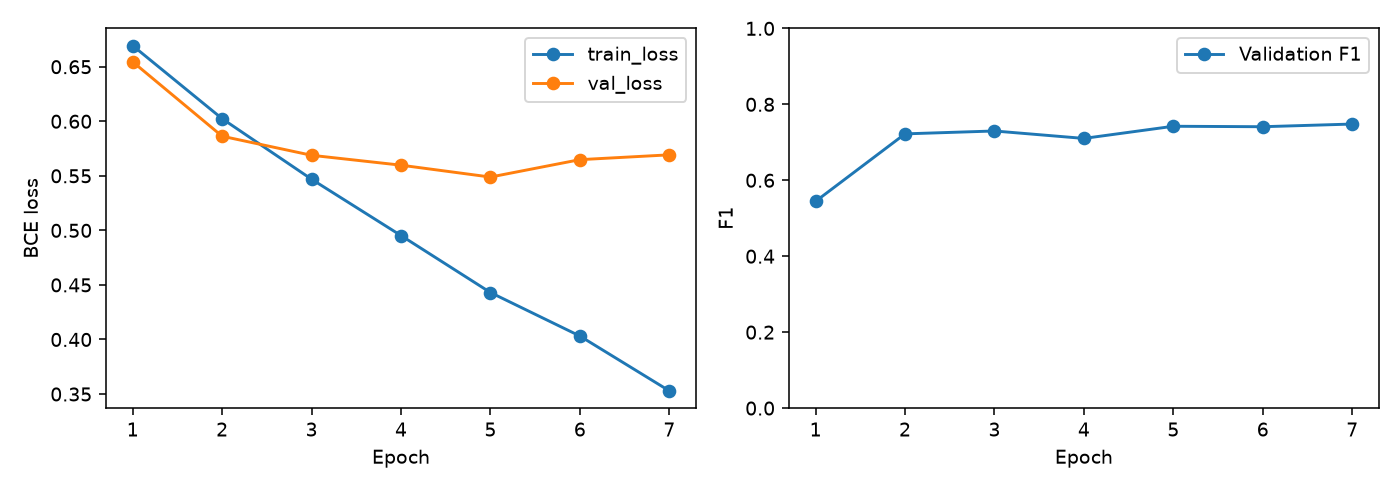

In [8]:
rnn_model, rnn_metrics, rnn_metadata = experiment.train("rnn")
print("Restored epoch:", rnn_metadata["best_epoch"], "checkpoint restored:", rnn_metadata["checkpoint_restored"])
display(pd.read_csv(RUN_DIR / "rnn" / "history.csv"))
display(Image(filename=str(RUN_DIR / "rnn" / "learning_curves.png")))

lstm: 2,692,225 trainable parameters


epoch 1: train_loss=0.6302, val_loss=0.5917, val_f1=0.7299


epoch 2: train_loss=0.5032, val_loss=0.4800, val_f1=0.7813


epoch 3: train_loss=0.3924, val_loss=0.4516, val_f1=0.7821


epoch 4: train_loss=0.3118, val_loss=0.4192, val_f1=0.8017


...

epoch 6: train_loss=0.1844, val_loss=0.4388, val_f1=0.8478


epoch 7: train_loss=0.1389, val_loss=0.4289, val_f1=0.8575


lstm: test F1=0.8460; artifacts: C:\Users\letie\Documents\Journals\NLP\outputs\full-20261027T170840-4f2309dd\lstm


Restored epoch: 5 checkpoint restored: True


,epoch,train_loss,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_macro_f1
0,1,0.630170,0.591683,0.6902,0.646986,0.8372,0.729904,0.683358
1,2,0.503188,0.480022,0.7826,0.785917,0.7768,0.781332,0.782593
2,3,0.392386,0.451641,0.7988,0.853025,0.7220,0.782062,0.797606
3,4,0.311813,0.419191,0.8174,0.876960,0.7384,0.801737,0.816253
4,5,0.246791,0.395963,0.8452,0.818685,0.8868,0.851382,0.844932
5,6,0.184350,0.438831,0.8376,0.797602,0.9048,0.847826,0.836863
6,7,0.138925,0.428878,0.8554,0.845049,0.8704,0.857537,0.855367


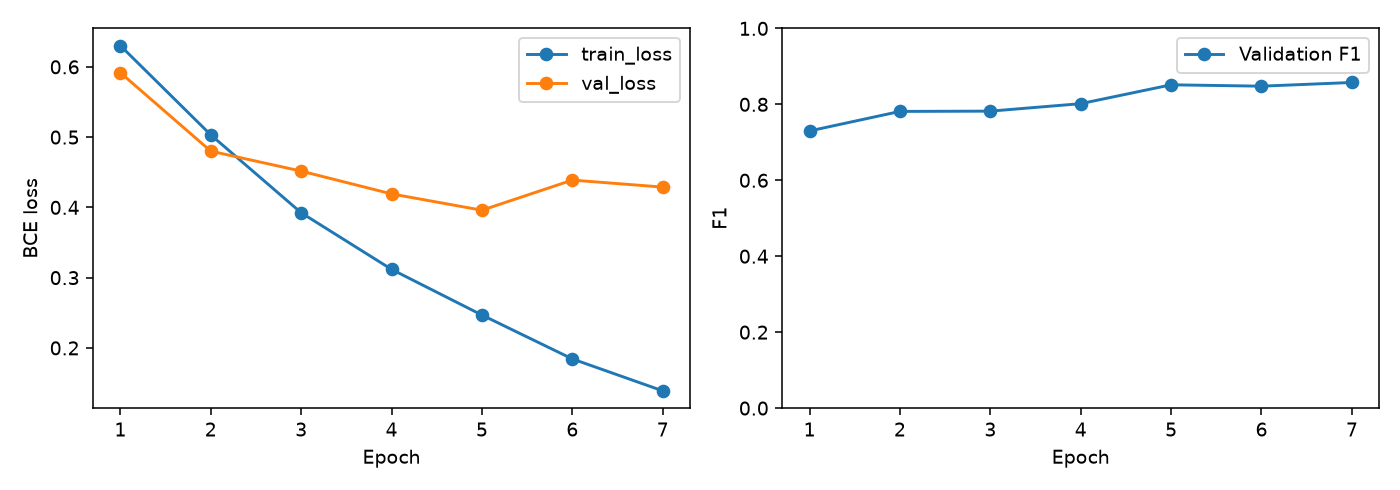

In [9]:
lstm_model, lstm_metrics, lstm_metadata = experiment.train("lstm")
print("Restored epoch:", lstm_metadata["best_epoch"], "checkpoint restored:", lstm_metadata["checkpoint_restored"])
display(pd.read_csv(RUN_DIR / "lstm" / "history.csv"))
display(Image(filename=str(RUN_DIR / "lstm" / "learning_curves.png")))

## 7. Final evaluation and comparison

Report accuracy, positive-class precision/recall/F1, macro-F1, confusion matrices, training seconds, and parameter counts. Timing excludes shared feature preparation and test evaluation; baseline time includes the C search and neural time includes training/validation/checkpointing. CPU and GPU times have different hardware costs.

Comparison reads saved results and joins predictions by review ID, validating the configuration and split identity first. Missing results are explicitly marked Not run, never filled with zero.

Comparison saved: C:\Users\letie\Documents\Journals\NLP\outputs\full-20261027T170840-4f2309dd\comparison


,model,status,accuracy,precision,recall,f1,macro_f1,training_seconds,parameter_count,device,best_config
0,logreg,complete,0.90232,0.902320,0.90232,0.902320,0.902320,3.486604,100001,cpu,"{""C"": 10.0}"
1,svm,complete,0.90088,0.902878,0.89840,0.900634,0.900879,3.535550,100001,cpu,"{""C"": 1.0}"
2,rnn,complete,0.75256,0.775048,0.71168,0.742014,0.752146,78.046786,2593153,cuda,"{""best_epoch"": 5}"
3,lstm,complete,0.84028,0.816598,0.87768,0.846038,0.840056,87.901606,2692225,cuda,"{""best_epoch"": 5}"


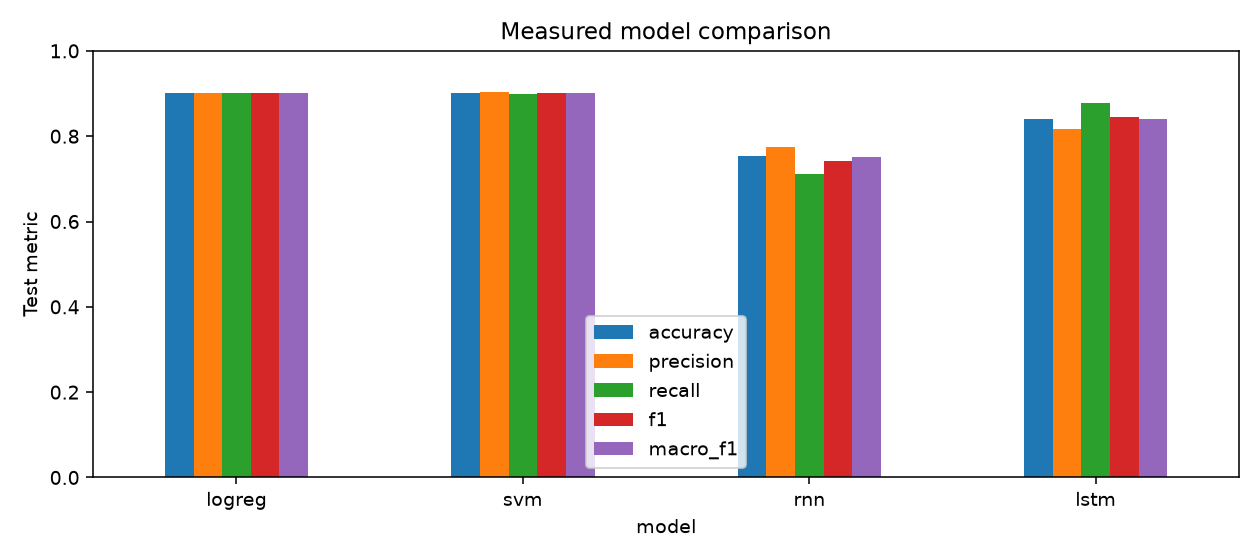

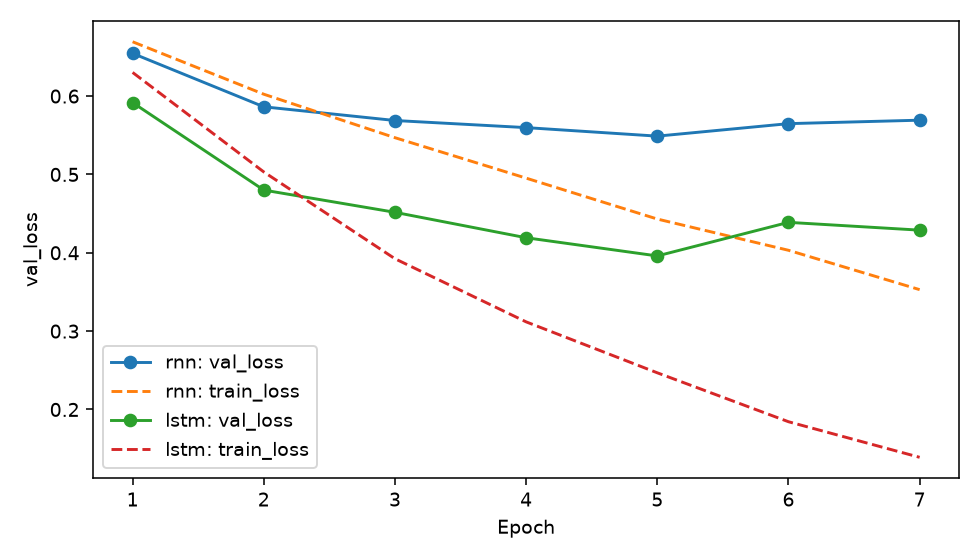

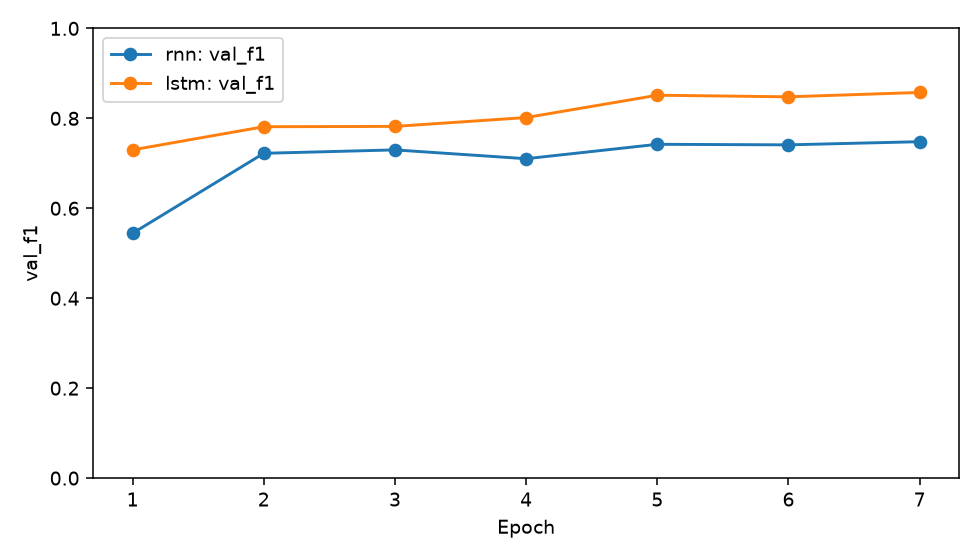

LOGREG


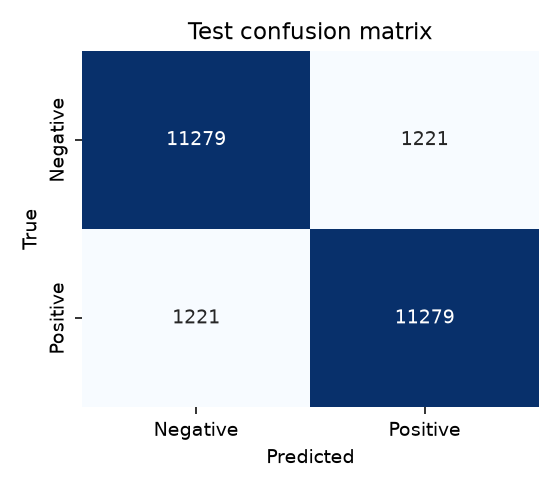

SVM


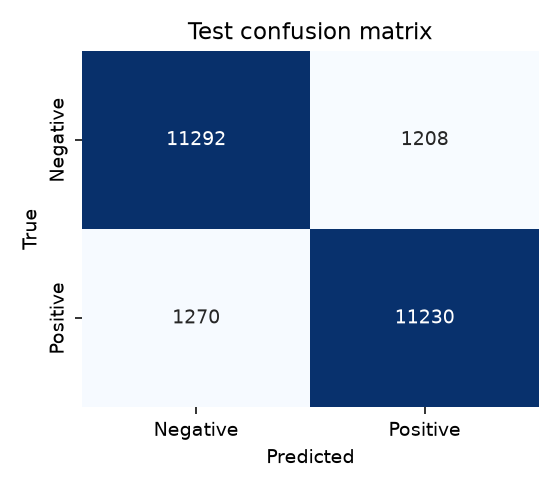

RNN


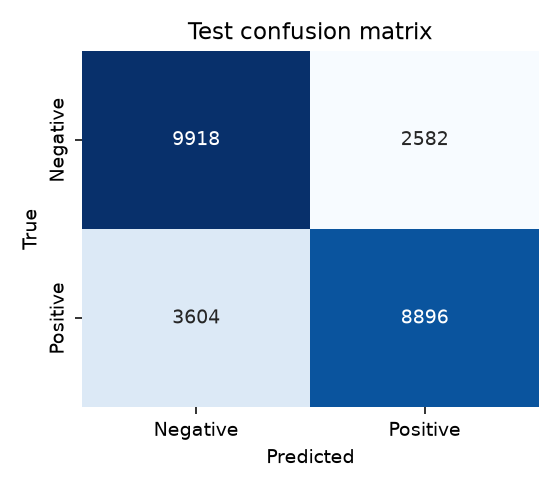

LSTM


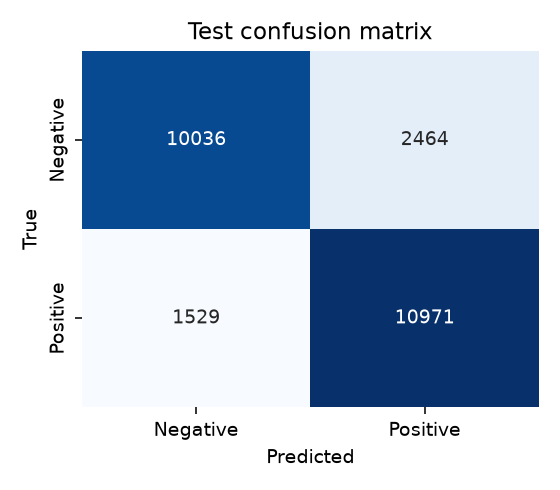

In [10]:
comparison = compare_results(RUN_DIR)
display(comparison)
for filename in ("metrics_bar_chart.png", "rnn_lstm_loss_curves.png", "rnn_lstm_f1_curves.png"):
    display(Image(filename=str(RUN_DIR / "comparison" / filename)))
for name in ("logreg", "svm", "rnn", "lstm"):
    print(name.upper())
    display(Image(filename=str(RUN_DIR / name / "confusion_matrix.png")))

## 8. Error analysis, conclusions, and export

Inspect up to ten examples on which at least one model made an error. Excerpts are limited to 500 characters. Look for negation, mixed sentiment, long reviews, and information near truncated endings. These examples are descriptive analysis, not a source for test-time tuning.

The generated report describes actual measurements. One seed cannot establish statistical significance or an architecture's universal superiority. GPU execution may vary across hardware and library versions despite fixed seeds.

In [11]:
display(pd.read_csv(RUN_DIR / "comparison" / "error_analysis.csv").fillna(""))
display(Markdown((RUN_DIR / "comparison" / "comparison.md").read_text(encoding="utf-8")))
print("Full experiment status:", "Completed" if MODE == "full" else "Not run in this execution")
print("Run directory:", RUN_DIR.resolve())

,review_id,true_label,logreg,svm,rnn,lstm,excerpt
0,test:100,0,0,0,1,0,"""cover girl"" is a lacklustre wwii musical with..."
1,test:1000,0,0,0,1,0,this film is about a struggling actor trying t...
2,test:10003,0,0,0,1,0,"wow, i was really disappointed. i wasn't reall..."
3,test:1001,0,0,0,1,1,"this experimental silent film, made in switzer..."
4,test:10011,0,0,0,1,1,tyra & the rest of the modeling world needs to...
5,test:10012,0,0,0,1,1,i would like to comment on how the girls are c...
6,test:10018,0,0,0,1,0,"(a possible minor spoiler) the first ""jurassic..."
7,test:10021,0,1,1,0,1,number 1 was really great summer popcorn fun. ...
8,test:10028,0,0,0,1,1,from the fertile imagination which brought you...
9,test:10029,0,1,1,0,1,looking for a real super bad movie? if you wan...


# IMDB model comparison

Run: `full-20261027T170840-4f2309dd`. Full IMDB evaluation on the fixed official test split.

| model | status | accuracy | precision | recall | f1 | macro_f1 | training_seconds | parameter_count | device | best_config |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| logreg | complete | 0.9023 | 0.9023 | 0.9023 | 0.9023 | 0.9023 | 3.4866 | 100001 | cpu | {"C": 10.0} |
| svm | complete | 0.9009 | 0.9029 | 0.8984 | 0.9006 | 0.9009 | 3.5356 | 100001 | cpu | {"C": 1.0} |
| rnn | complete | 0.7526 | 0.7750 | 0.7117 | 0.7420 | 0.7521 | 78.0468 | 2593153 | cuda | {"best_epoch": 5} |
| lstm | complete | 0.8403 | 0.8166 | 0.8777 | 0.8460 | 0.8401 | 87.9016 | 2692225 | cuda | {"best_epoch": 5} |

Among completed models, **logreg** has the highest measured test F1 (0.9023). This is an observed single-seed result, not a claim of statistical significance. Test results were not used to tune models.

Linear models use sparse word/bigram TF-IDF; neural models use learned word embeddings and truncated sequences. RNN and LSTM share dimensions and training rules, but LSTM has more trainable parameters. Baseline time includes the C search; neural time includes epochs, validation and checkpointing. Shared feature preparation and test evaluation are excluded. CPU/GPU timing differences limit direct cost comparisons.

Vanishing gradients, truncation of review endings and overfitting can affect neural results. Loss and validation F1 curves describe observed optimization; no architecture is assumed best in advance.

## Error examples

| review_id | true_label | logreg | svm | rnn | lstm | excerpt |
| --- | --- | --- | --- | --- | --- | --- |
| test:100 | 0 | 0 | 0 | 1 | 0 | "cover girl" is a lacklustre wwii musical with absolutely nothing memorable about it, save for its signature song, "long ago and far away." this film came out before gene kelly really hit his artistic stride, and while there are evidences of his burgeoning talent here, mostly he plays sidekick to rita hayworth. and there's the problem. rita hayworth is gorgeous, no doubt about that. but she's simply not a compelling screen presence. i've always found myself wanting to like her more than i actual |
| test:1000 | 0 | 0 | 0 | 1 | 0 | this film is about a struggling actor trying to find satisfaction in life, especially love which he has not had a taste of for 5 years. it basically is a film featuring a man with very poor social skills, and he says wrong things all the time. the plot is hollow and contrived. the main character, james, is lonely, but this theme of loneliness is not adequately explored. it is more like an empty statement which other subplots stem from. sadness and disappointment after being dumped are superficia |
| test:10003 | 0 | 0 | 0 | 1 | 0 | wow, i was really disappointed. i wasn't really planning on seeing this movie in the theater, and i wish i stuck to that plan. it really should be a made-for-tv movie. i was kind of excited to see it, as i'm a big fan of fairuza balk, but this movie didn't do her justice. infact i'm a little disappointed with the acting all around. what a horrible cover up of fairuza balk's tattoos, it bothered me every time i saw her shoulder. there was no flow to the movie, it was very hard to get into it. one |
| test:1001 | 0 | 0 | 0 | 1 | 1 | this experimental silent film, made in switzerland by an independent british film company, is chiefly remembered as paul robeson's first film. it's very artistic, with shots often seeming meaningless to the story, which is difficult to understand anyway because of the lack of enough inter-titles. from what i gathered, robeson's wife, adah, is in an inter-racial love affair with a white man called thorne. it doesn't bother the cigar-chomping owner of the bar/hotel where thorne lives (and she seem |
| test:10011 | 0 | 0 | 0 | 1 | 1 | tyra & the rest of the modeling world needs to know that real women like myself and my daughter don't care to see all the ridiculous modeling to sell something. weird locations, too much makeup & too much skin is not necessary. sex does not always sell when you are selling to women. the same goes for the horse stomping runway walk that looks unnatural. people come in all shapes & sizes & they need to have that on the show. my daughter has a 36" inseam, is tall & slender & a size 5, i am more ave |
| test:10012 | 0 | 0 | 0 | 1 | 1 | i would like to comment on how the girls are chosen. why is that their are always more white women chosen then their are black women. every episode their is always more white women then black one's. as if to say white women are better looking then black women. i would like for once see more black women then white. and it not just your show it's like that in a lot of shows always more white's. but i would have thought since you as the head honcho of the show you would see this yourself and have m |
| test:10018 | 0 | 0 | 0 | 1 | 0 | (a possible minor spoiler) the first "jurassic park" was an effective, but silly film that did it's job and was actually pretty good. the sequel "the lost world" had a few decent moments, but those were ruined by the lame end portion of the film which had a t-rex running amok in san diego. now in "jurassic park iii," what little story there was in the first one and the sequel, has been thrown out the window and replaced by a mere 90 minutes of basically non-stop action, which would have worked h |
| test:10021 | 0 | 1 | 1 | 0 | 1 | number 1 was really great summer popcorn fun. it was the modern jaws. number 2 is best summed up by jeff goldblum in the movie about being the stupidest idea in the history of stupid ideas (or something like that). number 3 is the obituary notice...jp has achieved all it ever will. once they realized they had no fresh ideas they should have just let sleeping dinos lie. that said. movie is ok if you don't mind knowing you already have seen it before. |
| test:10028 | 0 | 0 | 0 | 1 | 1 | from the fertile imagination which brought you the irresistible hercules (1983), comes its even more preposterous (read goofier) sequel: right off the bat, we get another unwieldy "beginning of time" prologue which even contrives to completely contradict these same events as set up in the first film!; a condensed montage of highlights from same is soon followed by a superman-like scrolling credits sequence. narrative-wise, here we have four rebellious gods who steal zeus' seven all-important (bu |
| test:10029 | 0 | 1 | 1 | 0 | 1 | looking for a real super bad movie? if you wanna have great fun, don't hesitate and check this one! ferrigno is incredibly bad but is also the best of this mediocrity. |


Full experiment status: Completed
Run directory: C:\Users\letie\Documents\Journals\NLP\outputs\full-20261027T170840-4f2309dd


In [12]:
import shutil
archive_path = shutil.make_archive(str(RUN_DIR), "zip", root_dir=RUN_DIR.parent, base_dir=RUN_DIR.name)
print("Artifact archive:", archive_path)
if IN_COLAB:
    from google.colab import files
    files.download(archive_path)

Artifact archive: C:\Users\letie\Documents\Journals\NLP\outputs\full-20261027T170840-4f2309dd.zip
